**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.

**Виконав:** Харченко Артьом, група ФІТ 3-10


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

In [2]:
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
print(os.listdir(path))

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
['kaggel_weather_2013_to_2024.csv']


In [3]:
df = pd.read_csv(os.path.join(path, "kaggel_weather_2013_to_2024.csv"))

print("Розмір:", df.shape)
display(df.head())
df.info()
display(df.describe())

Розмір: (3557, 29)


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non-null   object 
 15  Year

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


Підготовка даних

In [4]:
df["DATE"] = pd.to_datetime(df["DATE"], format="%m/%d/%Y")
df = df.sort_values("DATE")

# Unnamed: 0 - це старий індекс, а Year, month, dayofweek, *_humidity, heat_index і т.д.
# пораховані з інших стовпців, тому залишаємо тільки основні погодні показники
keep = ["DATE", "temp", "tempmax", "tempmin", "humidity", "precip", "windspeed", "sealevelpressure"]
df = df[keep]

df = df.set_index("DATE")
df.head()

,temp,tempmax,tempmin,humidity,precip,windspeed,sealevelpressure
DATE,,,,,,,
2013-04-14,28.7,37.7,23.1,39.7,2.0,22.3,1008.3
2013-04-15,28.6,37.5,21.1,41.7,0.0,17.6,1005.1
2013-04-16,31.7,40.1,21.9,30.7,0.0,27.7,1001.7
2013-04-17,29.9,36.4,21.0,27.4,0.0,22.3,1002.5
2013-04-18,30.6,37.5,21.7,23.7,0.0,12.4,1003.4


In [5]:
df.info()
print()
print("Період:", df.index.min().date(), "-", df.index.max().date())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   temp              3557 non-null   float64
 1   tempmax           3557 non-null   float64
 2   tempmin           3557 non-null   float64
 3   humidity          3557 non-null   float64
 4   precip            3557 non-null   float64
 5   windspeed         3557 non-null   float64
 6   sealevelpressure  3557 non-null   float64
dtypes: float64(7)
memory usage: 222.3 KB

Період: 2013-04-14 - 2024-11-30


In [6]:
print(df.isna().sum())
print()
print("Всього пропусків:", df.isna().sum().sum())
# пропусків немає, тому нічого заповнювати не треба

temp                0
tempmax             0
tempmin             0
humidity            0
precip              0
windspeed           0
sealevelpressure    0
dtype: int64

Всього пропусків: 0


Графік температури

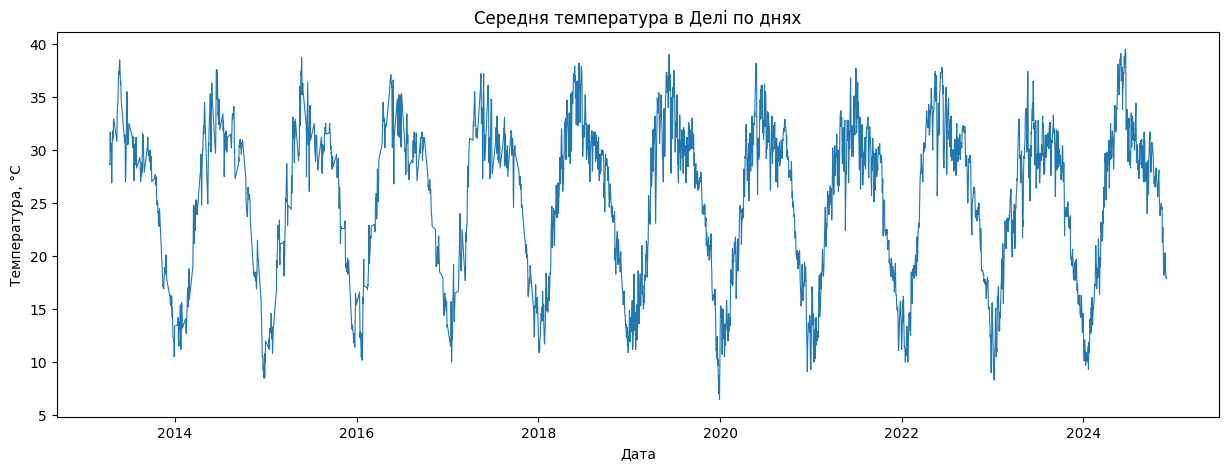

In [7]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df["temp"], linewidth=0.8)
plt.title("Середня температура в Делі по днях")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.show()

Ковзне середнє

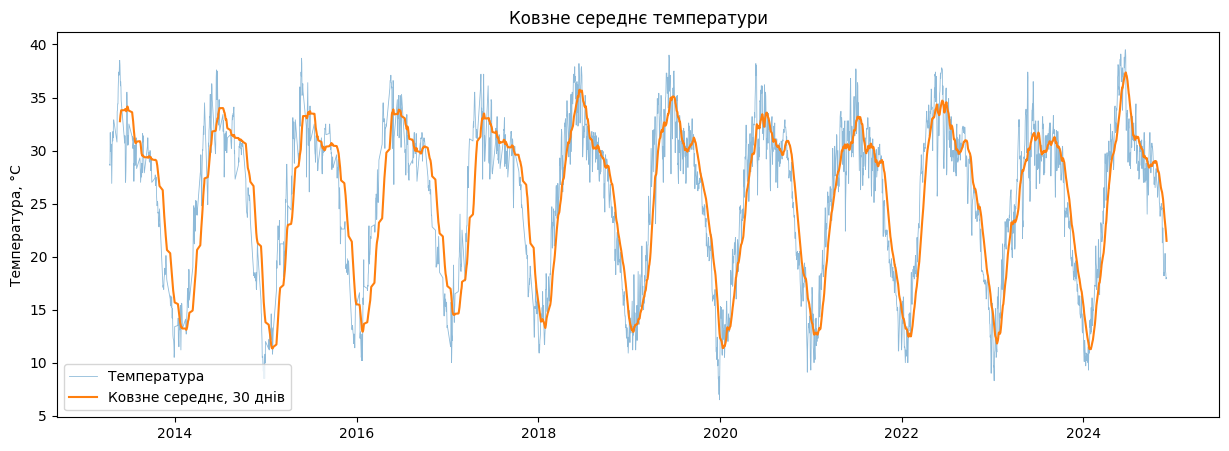

In [8]:
df["temp_ma30"] = df["temp"].rolling(window=30).mean()

plt.figure(figsize=(15, 5))
plt.plot(df.index, df["temp"], linewidth=0.6, alpha=0.5, label="Температура")
plt.plot(df.index, df["temp_ma30"], label="Ковзне середнє, 30 днів")
plt.title("Ковзне середнє температури")
plt.ylabel("Температура, °C")
plt.legend()
plt.show()

Розподіл температури

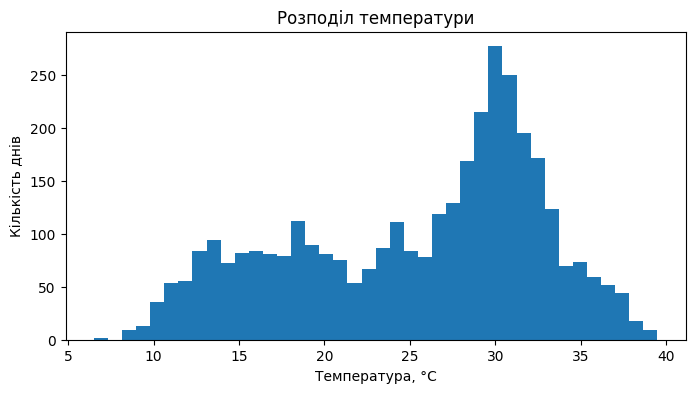

In [9]:
plt.figure(figsize=(8, 4))
plt.hist(df["temp"], bins=40)
plt.title("Розподіл температури")
plt.xlabel("Температура, °C")
plt.ylabel("Кількість днів")
plt.show()

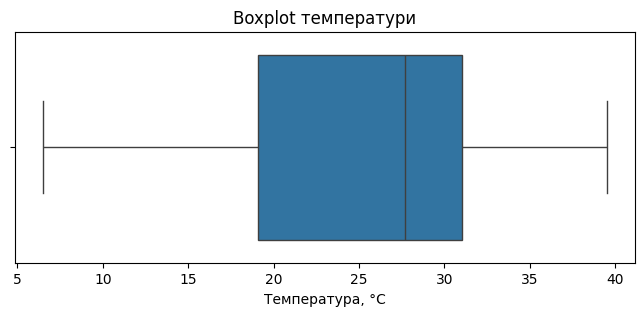

In [10]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["temp"])
plt.title("Boxplot температури")
plt.xlabel("Температура, °C")
plt.show()

Аналіз автокореляції
ACF

PACF

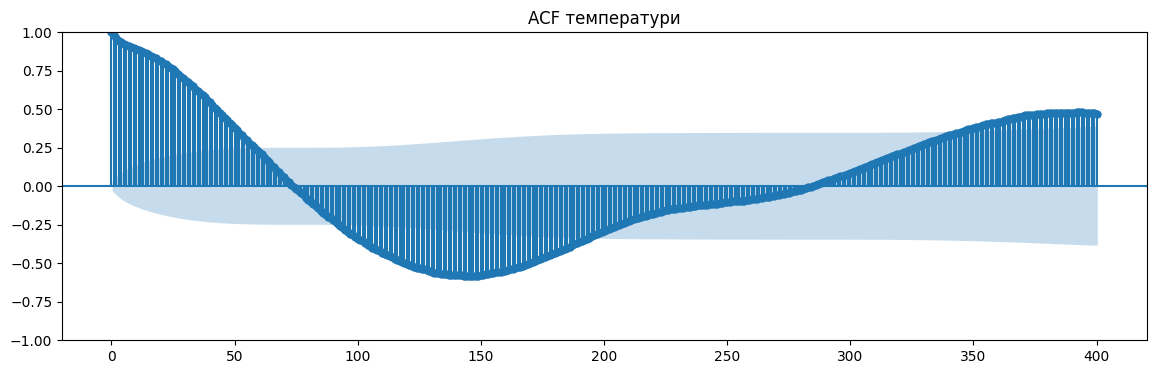

In [11]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(df["temp"], lags=400, ax=ax)
plt.title("ACF температури")
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

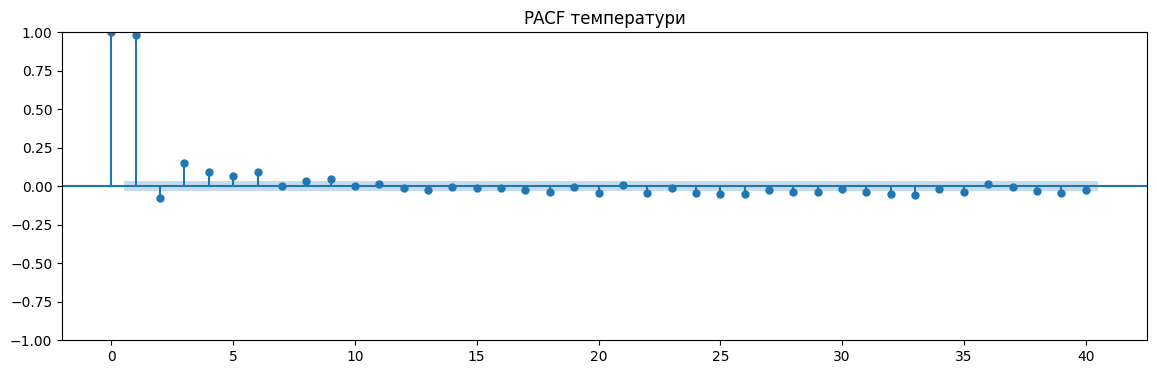

In [12]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_pacf(df["temp"], lags=40, ax=ax, method="ywm")
plt.title("PACF температури")
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

**Аналіз:** на графіку ACF автокореляція на перших лагах майже 1 і спадає дуже повільно, потім стає від'ємною, а на лагах близько 350-400 знову додатна. Тобто температура сильно залежить від попередніх днів і є річна сезонність (літо і зима повторюються щороку).

На графіку PACF значущі в основному перші лаги, найсильніше лаг 1, далі значення маленькі. Тобто температура найбільше залежить від вчорашньої. Тому для ARIMA беремо невеликий p = 2, а d = 1, бо ряд не стаціонарний (є сезонні коливання).

In [13]:
series = df["temp"]

# ділимо по часу: перші 80% - train, останні 20% - test (без перемішування)
split = int(len(series) * 0.8)
train = series.iloc[:split]
test = series.iloc[split:]

print("Train:", train.index.min().date(), "-", train.index.max().date(), "|", len(train), "записів")
print("Test:", test.index.min().date(), "-", test.index.max().date(), "|", len(test), "записів")

Train: 2013-04-14 - 2022-12-19 | 2845 записів
Test: 2022-12-20 - 2024-11-30 | 712 записів


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
# p=2 за PACF (значущі перші лаги), d=1 бо ряд не стаціонарний, q=2
arima = ARIMA(train.values, order=(2, 1, 2))
arima_fit = arima.fit()

arima_pred = pd.Series(arima_fit.forecast(steps=len(test)), index=test.index)
arima_pred.head()

,0
DATE,
2022-12-20,14.828089
2022-12-21,15.009728
2022-12-22,15.117278
2022-12-23,15.162084
2022-12-24,15.175065


In [15]:
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2845
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -4973.500
Date:                Tue, 13 Oct 2026   AIC                           9956.999
Time:                        06:58:57   BIC                           9986.764
Sample:                             0   HQIC                          9967.735
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7179      0.082      8.716      0.000       0.556       0.879
ar.L2         -0.1784      0.075     -2.378      0.017      -0.325      -0.031
ma.L1         -0.6778      0.083     -8.122      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

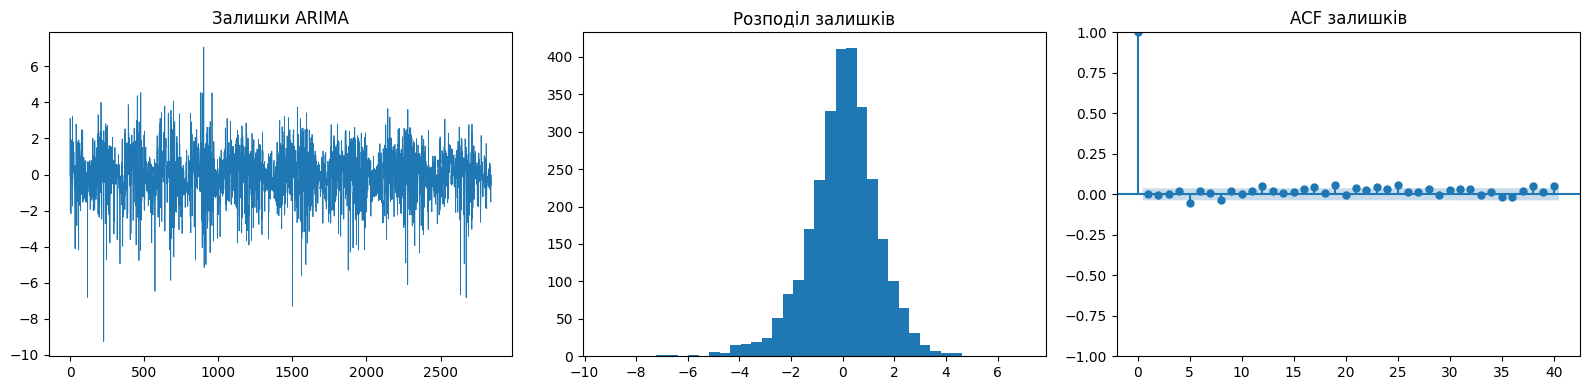

Середнє залишків: -0.0077
Стандартне відхилення залишків: 1.3908


In [16]:
residuals = arima_fit.resid[1:]  # перший залишок пропускаємо, бо через d=1 він некоректний

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(residuals, linewidth=0.6)
axes[0].set_title("Залишки ARIMA")
axes[1].hist(residuals, bins=40)
axes[1].set_title("Розподіл залишків")
plot_acf(residuals, lags=40, ax=axes[2])
axes[2].set_title("ACF залишків")
plt.tight_layout()
plt.show()

print("Середнє залишків:", round(residuals.mean(), 4))
print("Стандартне відхилення залишків:", round(residuals.std(), 4))

**Аналіз залишків:** залишки коливаються навколо нуля (середнє майже 0), розподіл схожий на нормальний, але лівий хвіст трохи довший, тобто бувають дні з різким похолоданням, які модель не передбачає. На ACF залишків майже всі лаги в межах синьої зони, тому зв'язок з попередніми днями модель описала нормально.

In [17]:
def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


def get_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAPE, %": float(mape(y_true, y_pred)),
    }


arima_metrics = get_metrics(test, arima_pred)
pd.Series(arima_metrics).round(3)

,0
MAE,10.916
RMSE,12.489
"MAPE, %",39.554


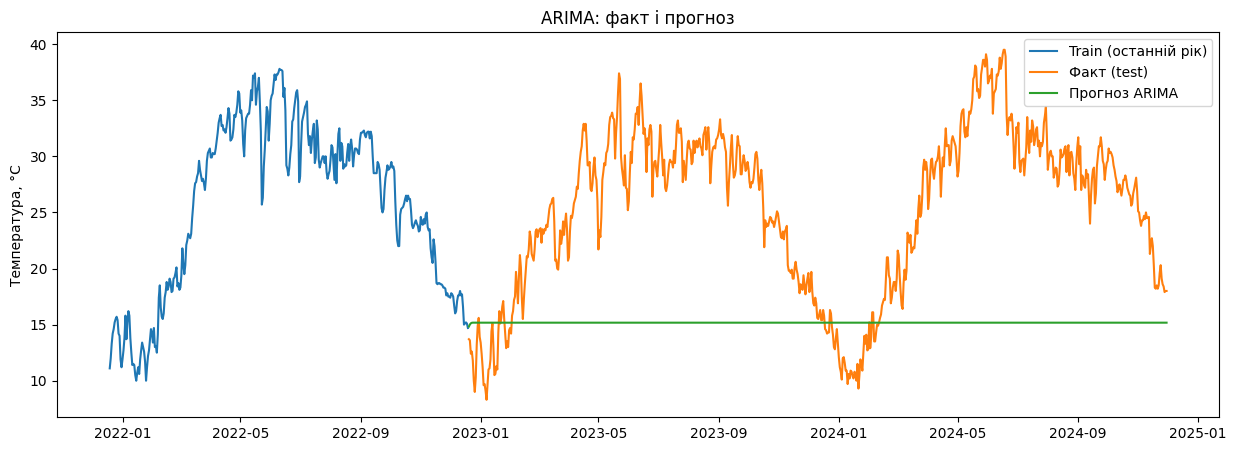

In [18]:
plt.figure(figsize=(15, 5))
plt.plot(train.index[-365:], train[-365:], label="Train (останній рік)")
plt.plot(test.index, test, label="Факт (test)")
plt.plot(arima_pred.index, arima_pred, label="Прогноз ARIMA")
plt.title("ARIMA: факт і прогноз")
plt.ylabel("Температура, °C")
plt.legend()
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [19]:
# Prophet потрібні стовпці ds (дата) і y (значення)
prophet_train = train.reset_index()
prophet_train.columns = ["ds", "y"]
prophet_train.head()

,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


In [20]:
prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
prophet.fit(prophet_train)

Прогноз

In [21]:
future = pd.DataFrame({"ds": test.index})
forecast = prophet.predict(future)

prophet_pred = pd.Series(forecast["yhat"].values, index=test.index)
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].head()

,ds,yhat,yhat_lower,yhat_upper
0,2022-12-20,13.808975,11.340338,16.473681
1,2022-12-21,13.637812,10.993052,16.238518
2,2022-12-22,13.489765,10.840443,16.310803
3,2022-12-23,13.365331,10.731786,15.949120
4,2022-12-24,13.264542,10.682916,15.896250


In [22]:
prophet_metrics = get_metrics(test, prophet_pred)
pd.Series(prophet_metrics).round(3)

,0
MAE,2.010
RMSE,2.596
"MAPE, %",9.056


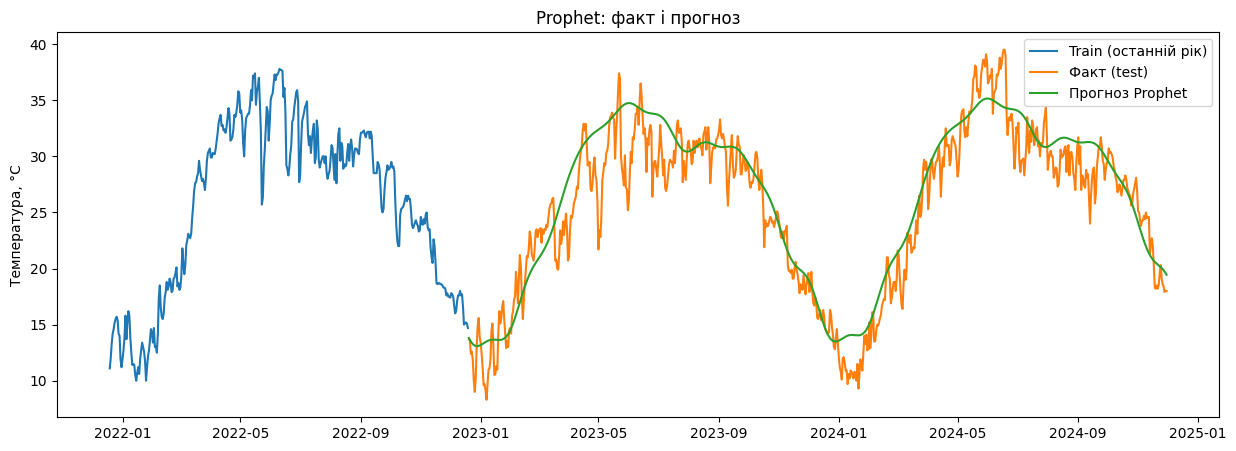

In [23]:
plt.figure(figsize=(15, 5))
plt.plot(train.index[-365:], train[-365:], label="Train (останній рік)")
plt.plot(test.index, test, label="Факт (test)")
plt.plot(prophet_pred.index, prophet_pred, label="Прогноз Prophet")
plt.title("Prophet: факт і прогноз")
plt.ylabel("Температура, °C")
plt.legend()
plt.show()

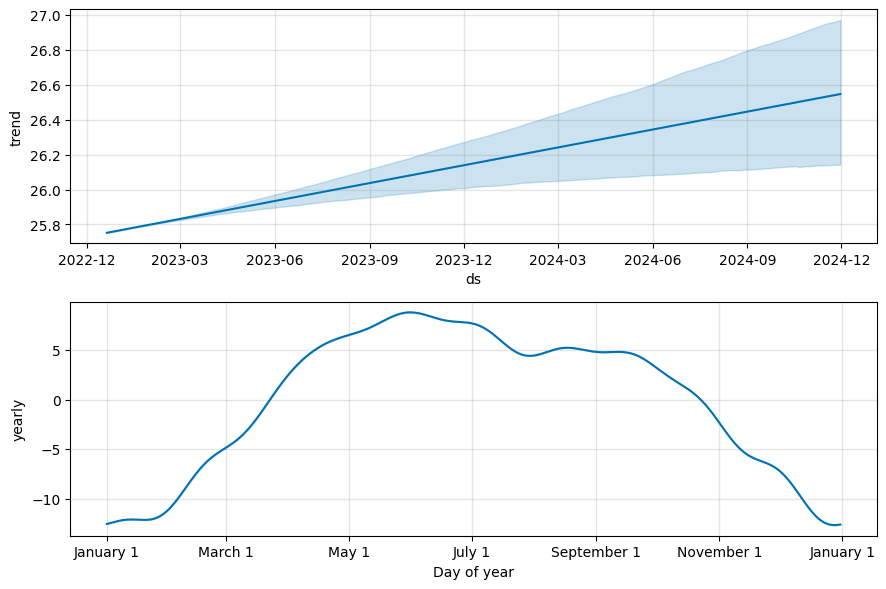

In [24]:
prophet.plot_components(forecast)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [25]:
window = 30  # прогнозуємо день за попередніми 30 днями

# scaler навчаємо тільки на train, щоб не підглядати в test
scaler = MinMaxScaler()
scaler.fit(train.values.reshape(-1, 1))
scaled = scaler.transform(series.values.reshape(-1, 1))

X_seq, y_seq, dates = [], [], []
for i in range(window, len(scaled)):
    X_seq.append(scaled[i - window:i, 0])
    y_seq.append(scaled[i, 0])
    dates.append(series.index[i])

X_seq = np.array(X_seq).reshape(-1, window, 1)
y_seq = np.array(y_seq)
dates = pd.DatetimeIndex(dates)
print("X:", X_seq.shape, "| y:", y_seq.shape)

X: (3527, 30, 1) | y: (3527,)


In [26]:
# у test потрапляють послідовності, де прогнозований день належить до test
is_test = dates >= test.index[0]

X_train_lstm, y_train_lstm = X_seq[~is_test], y_seq[~is_test]
X_test_lstm, y_test_lstm = X_seq[is_test], y_seq[is_test]

print("Train:", X_train_lstm.shape, "| Test:", X_test_lstm.shape)

Train: (2815, 30, 1) | Test: (712, 30, 1)


In [27]:
tf.keras.utils.set_random_seed(42)  # щоб результат був більш-менш однаковий при перезапуску

lstm = Sequential([
    Input(shape=(window, 1)),
    LSTM(64),
    Dense(1),
])
lstm.compile(optimizer="adam", loss="mse")

In [28]:
history = lstm.fit(
    X_train_lstm, y_train_lstm,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=2,  # один рядок на епоху
)

Epoch 1/20
80/80 - 4s - 44ms/step - loss: 0.0298 - val_loss: 0.0060
Epoch 2/20
80/80 - 1s - 6ms/step - loss: 0.0058 - val_loss: 0.0050
Epoch 3/20
80/80 - 1s - 6ms/step - loss: 0.0052 - val_loss: 0.0046
Epoch 4/20
80/80 - 0s - 6ms/step - loss: 0.0049 - val_loss: 0.0045
Epoch 5/20
80/80 - 1s - 7ms/step - loss: 0.0046 - val_loss: 0.0045
Epoch 6/20
80/80 - 0s - 6ms/step - loss: 0.0045 - val_loss: 0.0044
Epoch 7/20
80/80 - 1s - 9ms/step - loss: 0.0043 - val_loss: 0.0042
Epoch 8/20
80/80 - 2s - 21ms/step - loss: 0.0042 - val_loss: 0.0041
Epoch 9/20
80/80 - 1s - 11ms/step - loss: 0.0041 - val_loss: 0.0039
Epoch 10/20
80/80 - 1s - 7ms/step - loss: 0.0040 - val_loss: 0.0037
Epoch 11/20
80/80 - 0s - 6ms/step - loss: 0.0039 - val_loss: 0.0035
Epoch 12/20
80/80 - 1s - 6ms/step - loss: 0.0038 - val_loss: 0.0034
Epoch 13/20
80/80 - 0s - 6ms/step - loss: 0.0037 - val_loss: 0.0032
Epoch 14/20
80/80 - 0s - 6ms/step - loss: 0.0036 - val_loss: 0.0031
Epoch 15/20
80/80 - 0s - 6ms/step - loss: 0.0035 - val

In [29]:
lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,885 (198.77 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 33,924 (132.52 KB)

In [30]:
lstm_pred_scaled = lstm.predict(X_test_lstm, verbose=0)

# повертаємо значення в градуси
lstm_pred_values = scaler.inverse_transform(lstm_pred_scaled).flatten()
lstm_true_values = scaler.inverse_transform(y_test_lstm.reshape(-1, 1)).flatten()
print(lstm_pred_values[:5])
print(lstm_true_values[:5])

[15.0970745 14.588454  14.219743  13.581099  13.215786 ]
[13.7 13.6 12.4 12.6 11.8]


In [31]:
lstm_dates = dates[is_test]
lstm_pred = pd.Series(lstm_pred_values, index=lstm_dates)
print("Перша дата:", lstm_dates[0].date(), "| остання:", lstm_dates[-1].date(), "| записів:", len(lstm_dates))

Перша дата: 2022-12-20 | остання: 2024-11-30 | записів: 712


In [32]:
lstm_metrics = get_metrics(test.loc[lstm_dates], lstm_pred)
pd.Series(lstm_metrics).round(3)

,0
MAE,1.325
RMSE,1.660
"MAPE, %",5.613


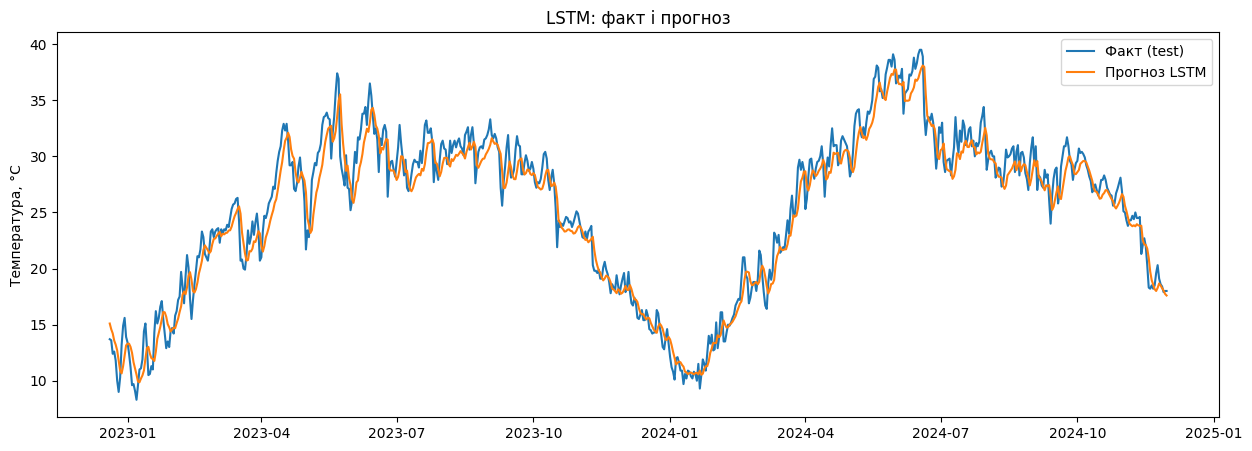

In [33]:
plt.figure(figsize=(15, 5))
plt.plot(test.index, test, label="Факт (test)")
plt.plot(lstm_pred.index, lstm_pred, label="Прогноз LSTM")
plt.title("LSTM: факт і прогноз")
plt.ylabel("Температура, °C")
plt.legend()
plt.show()

Порівняння моделей

,MAE,RMSE,"MAPE, %"
LSTM,1.325,1.660,5.613
Prophet,2.010,2.596,9.056
ARIMA,10.916,12.489,39.554


Найкраща модель за MAE: LSTM


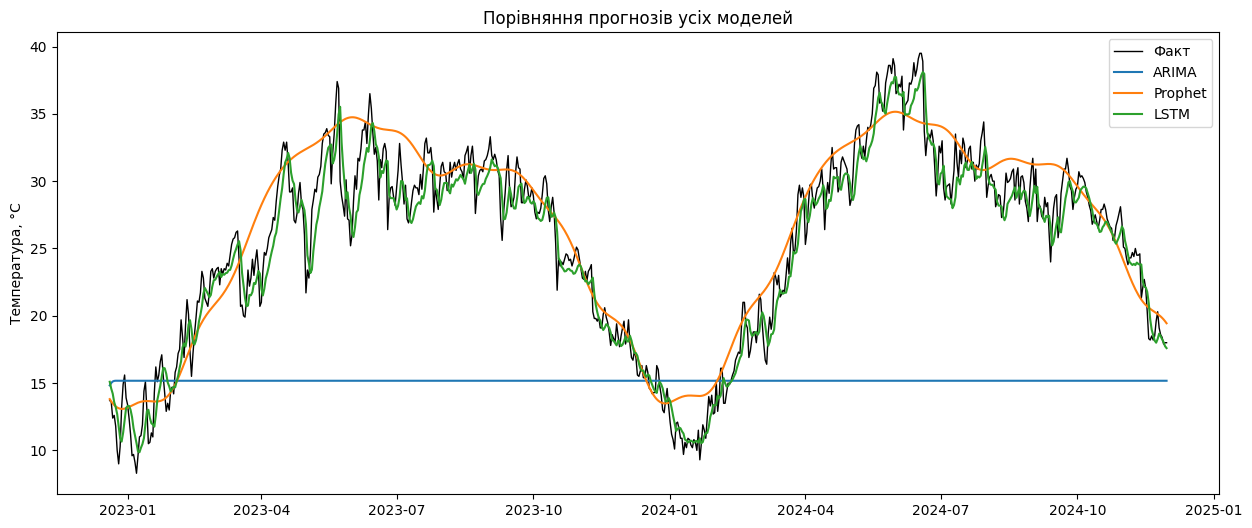

In [34]:
results = pd.DataFrame([arima_metrics, prophet_metrics, lstm_metrics], index=["ARIMA", "Prophet", "LSTM"])
results = results.sort_values("MAE")
display(results.round(3))
print("Найкраща модель за MAE:", results.index[0])

plt.figure(figsize=(15, 6))
plt.plot(test.index, test, color="black", linewidth=1, label="Факт")
plt.plot(arima_pred.index, arima_pred, label="ARIMA")
plt.plot(prophet_pred.index, prophet_pred, label="Prophet")
plt.plot(lstm_pred.index, lstm_pred, label="LSTM")
plt.title("Порівняння прогнозів усіх моделей")
plt.ylabel("Температура, °C")
plt.legend()
plt.show()

## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.

**Висновок:**

У роботі ми проаналізували щоденну температуру в Делі за 2013-2024 роки: побудували графік температури, ковзне середнє, гістограму, boxplot, ACF і PACF. Видно сильну річну сезонність: влітку температура доходить до 35-39 градусів, а взимку опускається до 10 і нижче.

Порівняння моделей на тестовій вибірці (з грудня 2022 по листопад 2024):
- ARIMA показала найгірший результат: MAE близько 10,9 °C, RMSE 12,5, MAPE майже 40%. Її прогноз на два роки вперед майже рівна лінія, бо проста ARIMA не враховує річну сезонність.
- Prophet значно краща: MAE близько 2 °C, RMSE 2,6, MAPE близько 9%. Вона добре вловила річну сезонність, але не повторює різкі зміни температури між днями.
- LSTM найкраща: MAE близько 1,1-1,4 °C, MAPE близько 5% (точні цифри трохи відрізняються при кожному запуску). Але треба враховувати, що LSTM прогнозує кожен день по реальних попередніх 30 днях, а ARIMA і Prophet прогнозують весь тестовий період одразу, тому в LSTM задача легша.

Отже, найкращу якість прогнозування показала модель LSTM, на другому місці Prophet, а найгірше ARIMA.